# 2. Decision Transformer

Código: `src/dt.py`. Entrenamiento: `python -m src.experimentos dt_train --logs random` (3 semillas).

## 2.1 Representación

Cada episodio de 20 pasos se convierte en 60 tokens: $\hat R_0, s_0, a_0, \hat R_1, s_1, a_1, \dots$

| Token | Contenido | Representación |
|---|---|---|
| $\hat R_t$ | retorno pendiente | $\hat R_t / 100$ → capa lineal |
| $s_t$ | grupo (0–7 o "desconocido") + rating anterior $r_{t-1}$ ("ninguno" en t = 0) | suma de dos embeddings |
| $a_t$ | ítem mostrado | embedding de ítems (752 + 1 de relleno) |

A los tres tokens del paso t se les suma el embedding del paso t y un embedding de tipo (R̂ / s / a).

- **Máscara causal** de 60 × 60: cada token sólo ve los anteriores.
- **Alineación de targets:** $a_t$ se predice desde la salida del token $s_t$. Esa salida vio $\hat R_{\le t}$, $s_{\le t}$ y $a_{<t}$, pero **no** $a_t$. El estado $s_t$ tiene $r_{t-1}$, nunca $r_t$.
- **Salida:** una logit por ítem, con pesos compartidos con el embedding de ítems.
- **Ítems ya mostrados:** sus logits se enmascaran con −∞, al entrenar y al recomendar.
- **Padding:** no hace falta. Todos los episodios miden 20. Al recomendar en el paso t, la secuencia mide t + 1 y en la posición de $a_t$ va un token de relleno que la salida de $s_t$ no ve.
- **Grupo oculto:** en el 30 % de los episodios de train el grupo se reemplaza por "desconocido".

Configuración: d = 64, 2 capas, 4 cabezas, dropout 0,1, AdamW (lr 1e-3, weight decay 0,01), OneCycle, recorte de gradiente 1, lotes de 256, 6 épocas. Se guarda el checkpoint con menor cross-entropy en validación. Elegimos un modelo chico porque se entrena en CPU.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
from src.utils import OUTPUTS
from src import reporte
pd.set_option("display.width", 200)

## 2.2 Test de no fuga (obligatorio)

Si se cambian $a_t$ y todo lo posterior (ítems, retornos y estados de los pasos > t), las logits del paso t no deben cambiar.

In [2]:
import torch
from src.dt import DecisionTransformer, prev_ratings_index
torch.manual_seed(0)
model = DecisionTransformer(752, 20, 64, 2, 4).eval()
B, T = 8, 20
items = torch.stack([torch.randperm(752)[:T] for _ in range(B)])
ratings = torch.randint(1, 6, (B, T)).float()
rtg = ratings.flip(1).cumsum(1).flip(1)
groups = torch.randint(0, 9, (B,))
for t in (0, 7, 19):
    base = model(rtg, items, prev_ratings_index(ratings), groups)[:, t]
    items2, rtg2, ratings2 = items.clone(), rtg.clone(), ratings.clone()
    items2[:, t:] = torch.randint(0, 752, items2[:, t:].shape)
    rtg2[:, t + 1:] = 0.0
    ratings2[:, t:] = torch.randint(1, 6, ratings2[:, t:].shape).float()
    out = model(rtg2, items2, prev_ratings_index(ratings2), groups)[:, t]
    print(f"t = {t:2d}: máxima diferencia en las logits = {(base - out).abs().max().item():.2e}")
    assert torch.allclose(base, out, atol=1e-5)
print("OK: la predicción del paso t no ve a_t ni nada posterior.")

t =  0: máxima diferencia en las logits = 0.00e+00
t =  7: máxima diferencia en las logits = 0.00e+00
t = 19: máxima diferencia en las logits = 0.00e+00
OK: la predicción del paso t no ve a_t ni nada posterior.


Los mismos controles, más el de la evaluación por lotes, están en `tests/test_modelos.py` (`python -m pytest tests`).

## 2.3 Curvas de entrenamiento

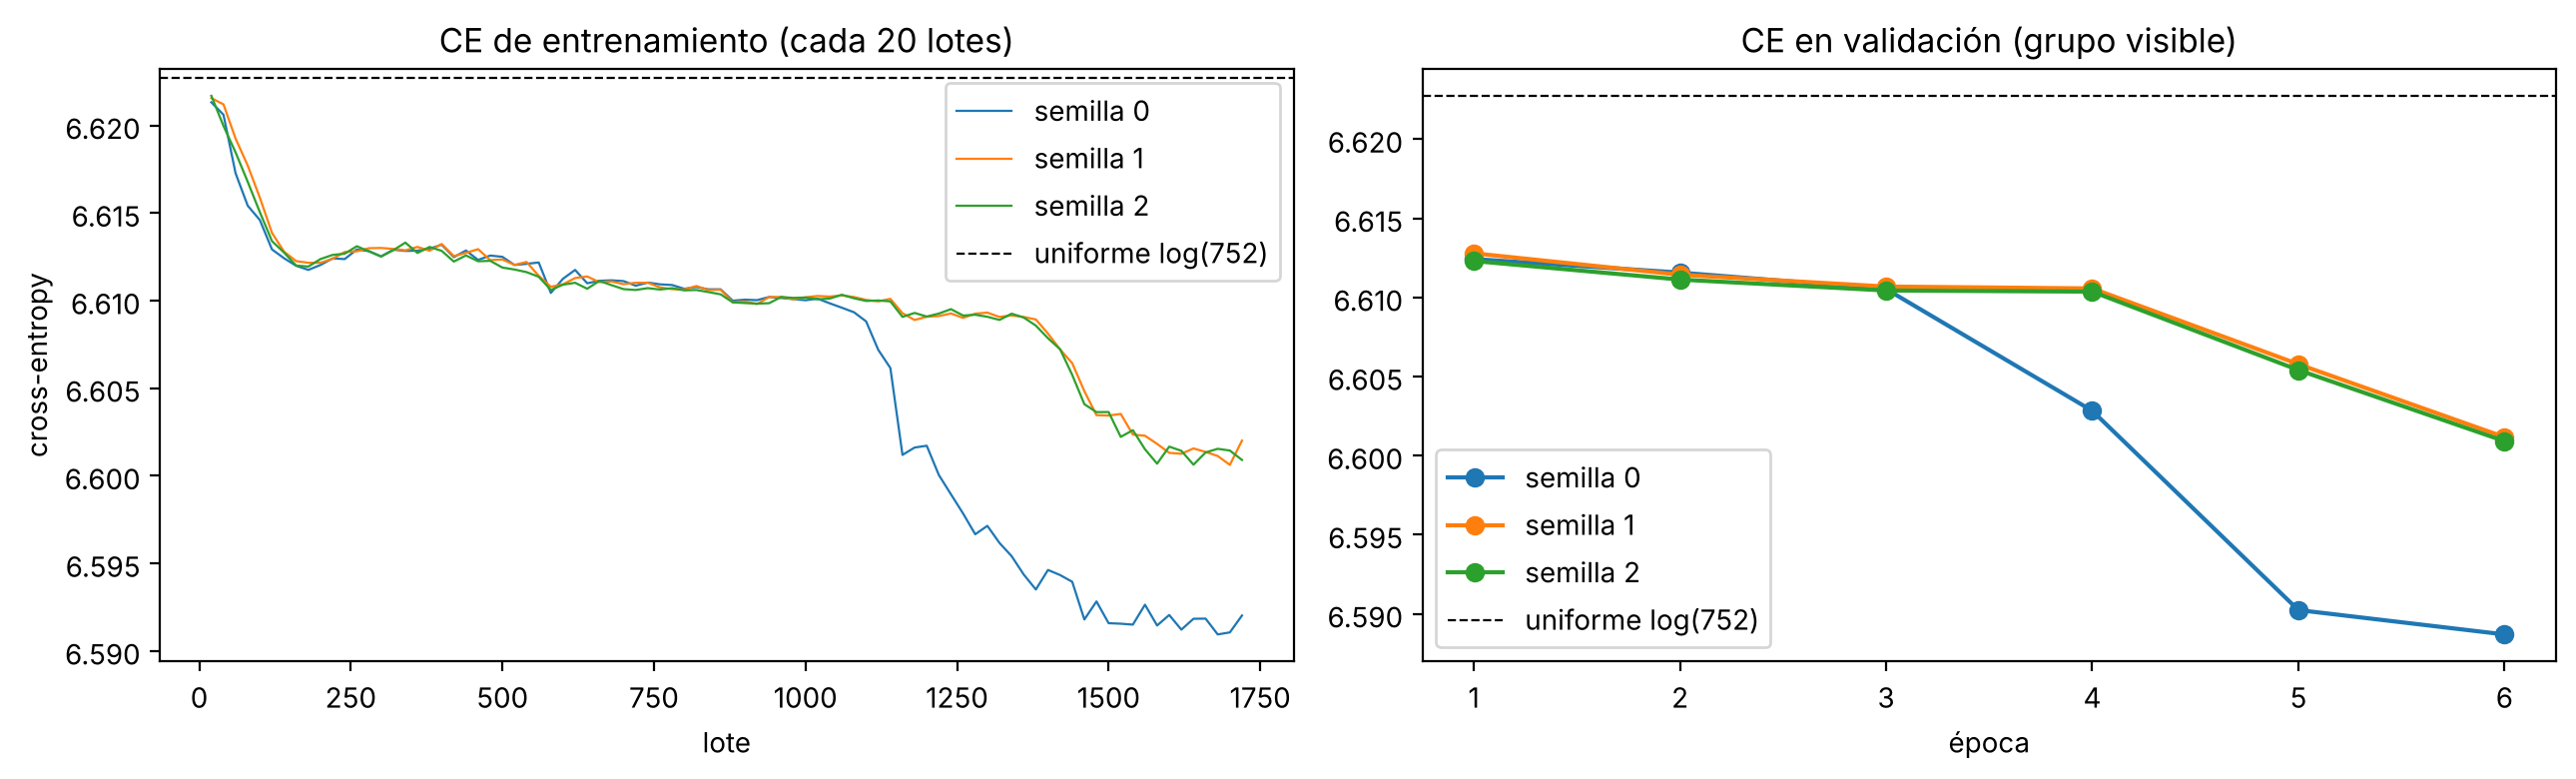

semilla 0: mejor CE val = 6.5887
semilla 1: mejor CE val = 6.6012
semilla 2: mejor CE val = 6.6009
referencias: uniforme sobre 752 ítems = 6.6227; uniforme sobre los ítems no mostrados = 6.6100


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for s in (0, 1, 2):
    h = json.loads((OUTPUTS / "dt" / "random" / f"seed{s}" / "history.json").read_text())
    axes[0].plot(h["step"], h["train_loss"], lw=0.8, label=f"semilla {s}")
    axes[1].plot(h["epoch"], h["val_loss"], marker="o", label=f"semilla {s}")
for ax in axes:
    ax.axhline(np.log(752), color="k", ls="--", lw=0.8, label="uniforme log(752)")
    ax.legend()
axes[0].set(title="CE de entrenamiento (cada 20 lotes)", xlabel="lote", ylabel="cross-entropy")
axes[1].set(title="CE en validación (grupo visible)", xlabel="época")
plt.tight_layout(); plt.show()
for s in (0, 1, 2):
    h = json.loads((OUTPUTS / "dt" / "random" / f"seed{s}" / "history.json").read_text())
    print(f"semilla {s}: mejor CE val = {h['best_val_loss']:.4f}")
print(f"referencias: uniforme sobre 752 ítems = {np.log(752):.4f}; uniforme sobre los ítems no mostrados = {np.mean(np.log(752 - np.arange(20))):.4f}")

**Lectura.** La cross-entropy baja muy poco respecto de la predicción uniforme (log(752) ≈ 6,62, o ≈ 6,61 si se descuentan los ítems ya mostrados). Era lo esperado: los logs son aleatorios, así que el ítem siguiente es casi impredecible. Lo único predecible es una correlación débil: en los episodios de retorno alto aparecen más los ítems que le gustan al grupo. Esa señal chica es justamente la que el DT usa al pedirle un retorno alto. La pérdida **no** mide la calidad de la recomendación; eso se mide con el protocolo.

## 2.4 Selección del retorno pedido (validación)

Candidatos: percentiles 10, 25, 50, 75, 90 y 99 de los retornos de train, el máximo y el máximo + 10 (fuera del soporte). Se elige el de mejor normalizado medio en validación (warm-up 0, grupo visible y oculto, 3 semillas de entrenamiento).

In [4]:
sel = pd.read_csv(OUTPUTS / "seleccion" / "dt_random_val.csv")
tab = sel.pivot_table(index=["candidate", "target"], columns="group_visible", values="normalized", aggfunc="mean")
tab.columns = ["oculto", "visible"]
tab["media"] = tab.mean(axis=1)
display(tab.sort_values("target").round(3))
print("elegido:", reporte.load_json("seleccion/dt_random_elegido.json"))

,,oculto,visible,media
candidate,target,,,
p10,46.0,-0.460,-0.492,-0.476
p25,57.0,-0.248,-0.278,-0.263
p50,65.0,-0.047,-0.070,-0.059
p75,73.0,0.159,0.148,0.153
p90,81.0,0.352,0.355,0.353
p99,89.0,0.496,0.495,0.495
max,97.0,0.535,0.536,0.536
max+10,107.0,0.537,0.537,0.537


elegido: {'candidate': 'max+10', 'target': 107.0, 'val_normalized': 0.5367220813636936, 'criterio': 'media de normalizado en val (warm-up 0, grupo visible y oculto, 3 semillas)'}


Los valores de validación **no** son comparables con los de test: en validación el catálogo de cada sesión se restringe a los ítems que el usuario valoró. Sirven para comparar configuraciones entre sí.